# Product Classification & Clustering
## Unsupervised Learning for Product Segmentation
This project applies unsupervised machine learning techniques to analyze and segment products based on product, merchant, category, and cluster-related attributes.
The project explores multiple feature representations and clustering approaches, including PCA, K-Means, DBSCAN, and an Autoencoder-based latent representation.
The goal is to identify meaningful product groups and evaluate how different representations affect clustering performance.
## Project Objectives
- Explore the structure and characteristics of the product dataset.
- Identify and prepare suitable features for unsupervised learning.
- Apply appropriate preprocessing and feature scaling techniques.
- Explore the data using PCA.
- Build a K-Means clustering baseline.
- Use an Autoencoder to learn a lower-dimensional latent representation.
- Apply clustering to the learned latent features.
- Compare clustering performance across different approaches.
- Analyze and interpret the resulting product segments.

## 1. Project Overview
This project analyzes product data using unsupervised machine learning techniques.
The workflow combines categorical feature engineering, K-Means clustering, Autoencoder-based representation learning, and DBSCAN to identify structure within product data.

In [1]:
import sys

print("Python version:", sys.version)
print("Python executable:", sys.executable)

Python version: 3.13.12 (tags/v3.13.12:1cbe481, Feb  3 2026, 18:22:25) [MSC v.1944 64 bit (AMD64)]
Python executable: c:\Users\domai\AppData\Local\Programs\Python\Python313\python.exe


In [5]:
%pip install numpy pandas matplotlib scikit-learn tensorflow ipykernel

   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ------------------------------- -------- 10.0/12.6 MB 54.3 MB/s eta 0:00:01
   ---------------------------------------- 12.6/12.6 MB 45.8 MB/s  0:00:00
   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
   ---------------------------------------- 10.7/10.7 MB 55.1 MB/s  0:00:00
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------  9.2/9.3 MB 51.5 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 42.3 MB/s  0:00:00
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   ----------------------------------- ---- 7.3/8.2 MB 35.8 MB/s eta 0:00:01
   ---------------------------------------- 8.2/8.2 MB 31.4 MB/s  0:00:00
   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
    --------------------------------------- 7.3/351.2 MB 36.1 MB/s eta 0:00:10
   - ----------------------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
# Import Libraries

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.layers import Input, Dense

print("All libraries imported successfully.")


All libraries imported successfully.


In [37]:
feature_df = df[["Merchant ID", "Category ID"]].copy()

In [38]:
feature_df.head()

,Merchant ID,Category ID
0,1,2612
1,2,2612
2,3,2612
3,4,2612
4,5,2612


In [39]:
feature_df.isnull().sum()

Merchant ID    0
Category ID    0
dtype: int64

In [40]:
feature_df.dtypes

Merchant ID    int64
Category ID    int64
dtype: object

In [41]:
feature_df = feature_df.astype(str)

feature_df.dtypes

Merchant ID    str
Category ID    str
dtype: object

In [42]:
feature_df = pd.get_dummies(
    feature_df,
    columns=["Merchant ID", "Category ID"],
    dtype=int
)

feature_df.head()

,Merchant ID_1,Merchant ID_10,Merchant ID_100,Merchant ID_101,Merchant ID_103,Merchant ID_105,Merchant ID_106,Merchant ID_107,Merchant ID_109,Merchant ID_11,...,Category ID_2612,Category ID_2614,Category ID_2615,Category ID_2617,Category ID_2618,Category ID_2619,Category ID_2620,Category ID_2621,Category ID_2622,Category ID_2623
0,1,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0


In [43]:
print("Feature shape:", feature_df.shape)
print("Original data shape:", df.shape)

Feature shape: (35311, 316)
Original data shape: (35311, 7)


In [44]:
X = feature_df.values

print("X shape:", X.shape)
print("Data type:", X.dtype)

X shape: (35311, 316)
Data type: int64


In [51]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled shape:", X_scaled.shape)
print("Data type:", X_scaled.dtype)

Scaled shape: (35311, 316)
Data type: float64


In [52]:
print("PCA shape:", X_pca.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())

PCA shape: (35311, 2)
Explained variance ratio: [0.00637636 0.00595221]
Total explained variance: 0.012328573243662412


In [53]:
pca_full = PCA()
pca_full.fit(X_scaled)

cumulative_variance = np.cumsum(
    pca_full.explained_variance_ratio_
)

print("Variance explained by first 2 components:",
      cumulative_variance[1])

print("Components needed for 80% variance:",
      np.argmax(cumulative_variance >= 0.80) + 1)

Variance explained by first 2 components: 0.012328573243662412
Components needed for 80% variance: 248


## 2. Data Loading & Initial Exploration

The dataset is loaded and inspected to understand its structure, dimensions, and available product attributes.

In [45]:
import urllib.request
import zipfile
import os
# Download dataset
url = "https://archive.ics.uci.edu/static/public/837/product+classification+and+clustering.zip"
zip_path = "product_classification_clustering.zip"
urllib.request.urlretrieve(url, zip_path)
# Extract dataset
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("data")
print("Dataset downloaded and extracted successfully.")

Dataset downloaded and extracted successfully.


In [46]:
for root, dirs, files in os.walk("data"):
    for file in files:
        print(os.path.join(root, file))

data\pricerunner_aggregate.csv


In [47]:
# Load dataset
csv_path = "data/pricerunner_aggregate.csv"
df = pd.read_csv(csv_path)
print("Dataset loaded successfully.")
print("Shape:", df.shape)
# Display the first 5 rows
df.head()

Dataset loaded successfully.
Shape: (35311, 7)


,Product ID,Product Title,Merchant ID,Cluster ID,Cluster Label,Category ID,Category Label
0,1,apple iphone 8 plus 64gb silver,1,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
1,2,apple iphone 8 plus 64 gb spacegrau,2,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
2,3,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...,3,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
3,4,apple iphone 8 plus 64gb space grey,4,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
4,5,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,5,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones


## 3. Exploratory Data Analysis
Before preprocessing the data, we examine the dataset structure, data types, missing values, and duplicated records.

In [48]:
# Exploratory Data Analysis

print("===== DATASET INFO =====")
df.info()

print("\n===== MISSING VALUES =====")
print(df.isnull().sum())

print("\n===== DUPLICATE ROWS =====")
print("Duplicate rows:", df.duplicated().sum())

print("\n===== UNIQUE VALUES =====")
print(df.nunique())

===== DATASET INFO =====
<class 'pandas.DataFrame'>
RangeIndex: 35311 entries, 0 to 35310
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Product ID       35311 non-null  int64
 1   Product Title    35311 non-null  str  
 2    Merchant ID     35311 non-null  int64
 3    Cluster ID      35311 non-null  int64
 4    Cluster Label   35311 non-null  str  
 5    Category ID     35311 non-null  int64
 6    Category Label  35311 non-null  str  
dtypes: int64(4), str(3)
memory usage: 1.9 MB

===== MISSING VALUES =====
Product ID         0
Product Title      0
 Merchant ID       0
 Cluster ID        0
 Cluster Label     0
 Category ID       0
 Category Label    0
dtype: int64

===== DUPLICATE ROWS =====
Duplicate rows: 0

===== UNIQUE VALUES =====
Product ID         35311
Product Title      30993
 Merchant ID         306
 Cluster ID        13233
 Cluster Label     12849
 Category ID          10
 Category Label       10


Category column: Category ID
Merchant column: Merchant ID


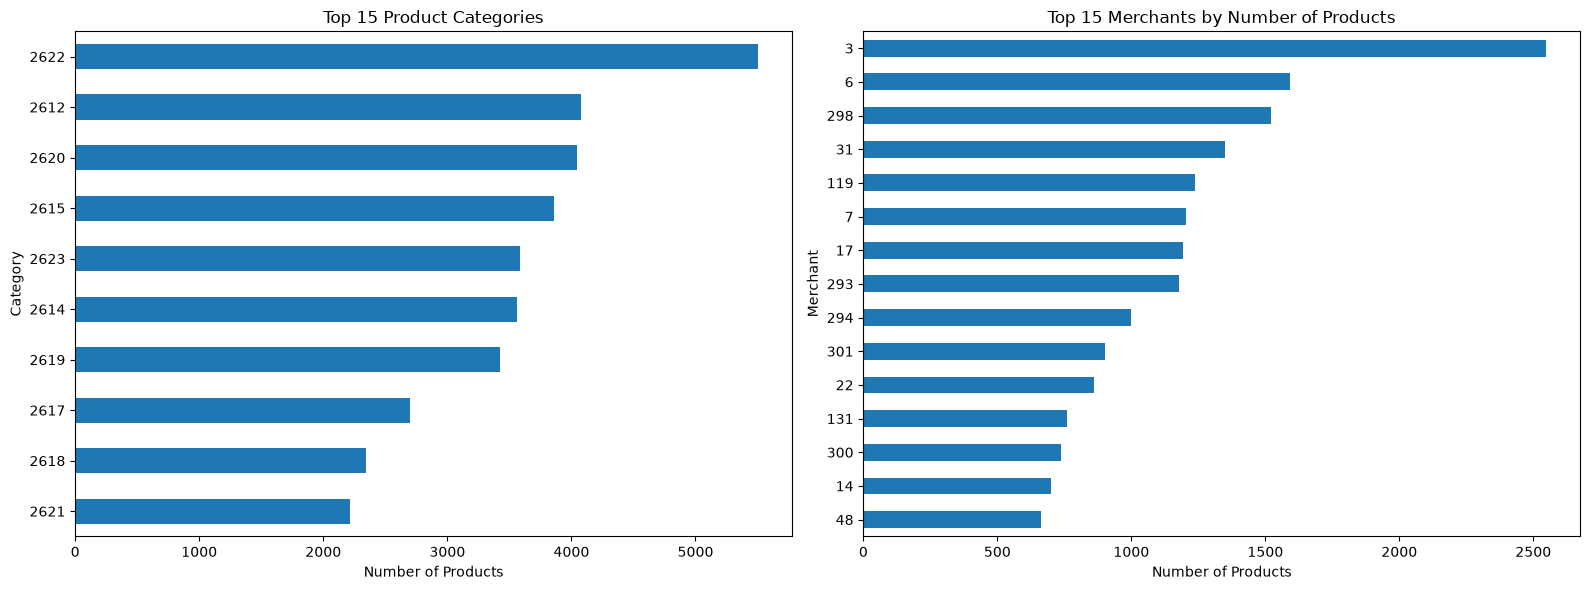

In [49]:
# Normalize column names
df.columns = [c.strip() for c in df.columns]

# Find category and merchant columns case-insensitively
cat_col = next((c for c in df.columns if "category" in c.lower()), None)
merchant_col = next((c for c in df.columns if "merchant" in c.lower()), None)

print("Category column:", cat_col)
print("Merchant column:", merchant_col)

if cat_col is None or merchant_col is None:
    raise ValueError(
        f"Could not find category/merchant columns. "
        f"Available columns: {list(df.columns)}"
    )

# Visualize category and merchant distributions
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

df[cat_col].value_counts(dropna=False).head(15).sort_values().plot(
    kind="barh", ax=axes[0]
)
axes[0].set_title("Top 15 Product Categories")
axes[0].set_xlabel("Number of Products")
axes[0].set_ylabel("Category")

df[merchant_col].value_counts(dropna=False).head(15).sort_values().plot(
    kind="barh", ax=axes[1]
)
axes[1].set_title("Top 15 Merchants by Number of Products")
axes[1].set_xlabel("Number of Products")
axes[1].set_ylabel("Merchant")

plt.tight_layout()
plt.show()

## 4. Feature Engineering & Preprocessing

In [50]:
# Select features for clustering

print("Available columns:")
print(df.columns.tolist())

Available columns:
['Product ID', 'Product Title', 'Merchant ID', 'Cluster ID', 'Cluster Label', 'Category ID', 'Category Label']


In [14]:
# Feature Engineering
# Exclude identifiers, product text, and existing cluster labels
# to avoid data leakage.

feature_df = df[["Merchant ID", "Category ID"]].copy()

# Convert categorical IDs to numeric values
feature_df["Merchant ID"] = pd.to_numeric(
    feature_df["Merchant ID"], errors="coerce"
)
feature_df["Category ID"] = pd.to_numeric(
    feature_df["Category ID"], errors="coerce"
)

# Remove rows with missing feature values
feature_df = feature_df.dropna().reset_index(drop=True)

print("Features used for clustering:")
print(feature_df.columns.tolist())

print("\nFeature shape:", feature_df.shape)
print("\nMissing values:")
print(feature_df.isnull().sum())

Features used for clustering:
['Merchant ID', 'Category ID']

Feature shape: (35311, 2)

Missing values:
Merchant ID    0
Category ID    0
dtype: int64


In [15]:
feature_df.head()

,Merchant ID,Category ID
0,1,2612
1,2,2612
2,3,2612
3,4,2612
4,5,2612


In [16]:
# Feature Engineering

feature_df = df[["Merchant ID", "Category ID"]].copy()

# Treat IDs as categorical features
feature_df = feature_df.astype(str)

# One-hot encode categorical features
X = pd.get_dummies(
    feature_df,
    columns=["Merchant ID", "Category ID"],
    dtype=float
)

print("Encoded feature shape:", X.shape)
print("Missing values:", X.isnull().sum().sum())

X.head()

Encoded feature shape: (35311, 316)
Missing values: 0


,Merchant ID_1,Merchant ID_10,Merchant ID_100,Merchant ID_101,Merchant ID_103,Merchant ID_105,Merchant ID_106,Merchant ID_107,Merchant ID_109,Merchant ID_11,...,Category ID_2612,Category ID_2614,Category ID_2615,Category ID_2617,Category ID_2618,Category ID_2619,Category ID_2620,Category ID_2621,Category ID_2622,Category ID_2623
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 5. Dimensionality Reduction

The one-hot encoded feature space contains 316 dimensions. PCA is applied to reduce dimensionality, preserve the main sources of variation, and provide a compact representation for visualization and subsequent clustering analysis.

Scaled feature shape: (35311, 316)
PCA shape: (35311, 2)
Explained variance ratio: [0.00637636 0.00595221]
Total explained variance: 1.23%


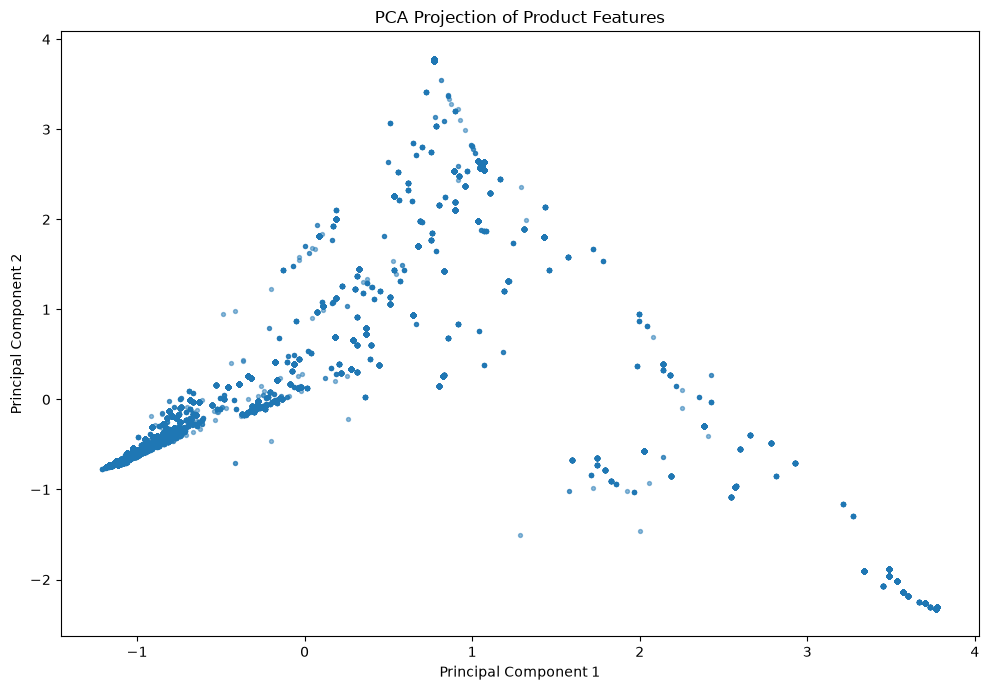

In [17]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled feature shape:", X_scaled.shape)

# PCA for dimensionality reduction
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print("PCA shape:", X_pca.shape)
print(f"Explained variance ratio: {pca.explained_variance_ratio_}")
print(f"Total explained variance: {pca.explained_variance_ratio_.sum():.2%}")
plt.figure(figsize=(10, 7))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    s=8,
    alpha=0.5
)

plt.title("PCA Projection of Product Features")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

80% variance: 248 components
90% variance: 279 components
95% variance: 295 components


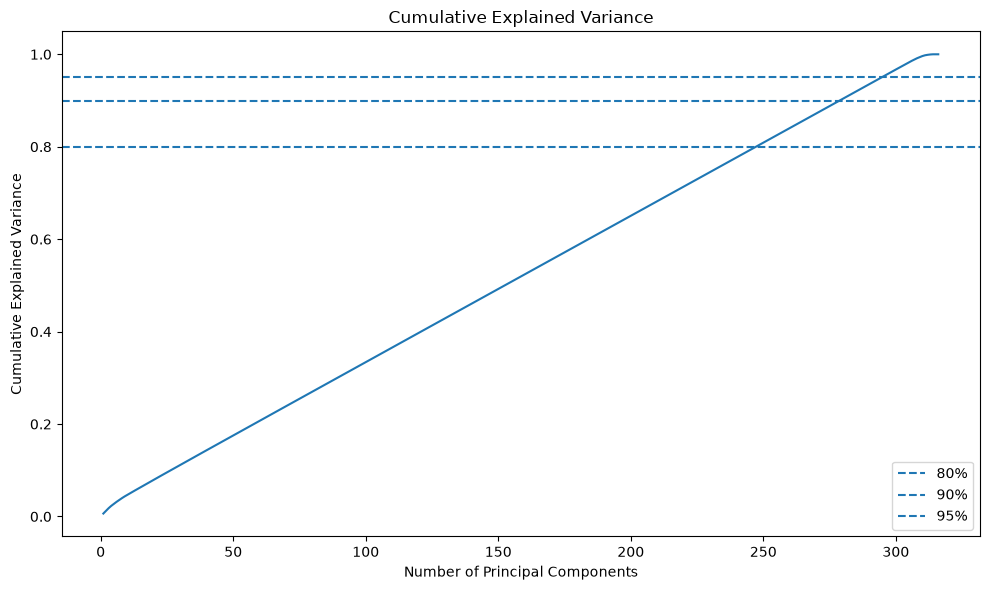

In [18]:
# PCA explained variance analysis

pca_full = PCA()
pca_full.fit(X_scaled)

cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

# Find number of components needed to retain 80%, 90%, and 95% variance
for threshold in [0.80, 0.90, 0.95]:
    n_components = np.argmax(cumulative_variance >= threshold) + 1
    print(f"{threshold:.0%} variance: {n_components} components")

# Plot cumulative explained variance
plt.figure(figsize=(10, 6))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance
)

plt.axhline(0.80, linestyle="--", label="80%")
plt.axhline(0.90, linestyle="--", label="90%")
plt.axhline(0.95, linestyle="--", label="95%")

plt.title("Cumulative Explained Variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.legend()
plt.tight_layout()
plt.show()

## 6. K-Means Clustering Baseline

K-Means is first applied to the standardized feature space as a baseline clustering method. The optimal number of clusters is evaluated using the Silhouette Score.

In [54]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Evaluate different numbers of clusters
k_values = range(2, 11)
silhouette_scores = []

kmeans_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    kmeans_scores.append(score)

    print(f"K={k}, Silhouette Score={score:.4f}")

K=2, Silhouette Score=-0.0340
K=3, Silhouette Score=-0.0323
K=4, Silhouette Score=-0.0933
K=5, Silhouette Score=-0.0785
K=6, Silhouette Score=-0.0514
K=7, Silhouette Score=-0.2104
K=8, Silhouette Score=-0.1852
K=9, Silhouette Score=-0.1974
K=10, Silhouette Score=-0.1788


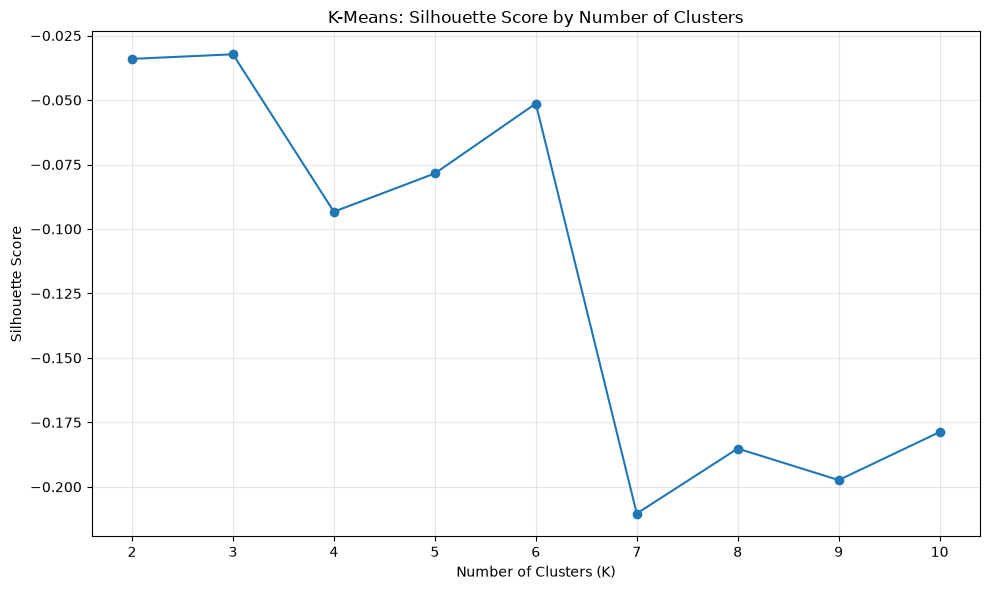

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    list(k_values),
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("K-Means: Silhouette Score by Number of Clusters")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Autoencoder-Based Representation Learning

The baseline clustering results indicate that the original one-hot feature space does not provide well-separated clusters.

An Autoencoder is therefore used to learn a compact latent representation of the product features. The learned representation will then be used as input for clustering.

In [21]:
# Autoencoder

from tensorflow.keras import Model
from tensorflow.keras.layers import Input, Dense

input_dim = X_scaled.shape[1]
latent_dim = 16

# Encoder
inputs = Input(shape=(input_dim,))
encoded = Dense(128, activation="relu")(inputs)
encoded = Dense(64, activation="relu")(encoded)
latent = Dense(latent_dim, activation="relu", name="latent_space")(encoded)

# Decoder
decoded = Dense(64, activation="relu")(latent)
decoded = Dense(128, activation="relu")(decoded)
outputs = Dense(input_dim, activation="linear")(decoded)

# Autoencoder model
autoencoder = Model(inputs, outputs)

autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 316)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        40,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_space (Dense)            │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 316)            │        40,764 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 100,044 (390.80 KB)

 Trainable params: 100,044 (390.80 KB)

 Non-trainable params: 0 (0.00 B)

In [56]:
# Train Autoencoder

hhistory = autoencoder.fit(
    X_scaled,
    X_scaled,
    epochs=50,
    batch_size=256,
    shuffle=True,
    validation_split=0.2
)

Epoch 1/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5842 - val_loss: 0.6667
Epoch 2/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5840 - val_loss: 0.6671
Epoch 3/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5839 - val_loss: 0.6676
Epoch 4/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5837 - val_loss: 0.6680
Epoch 5/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5835 - val_loss: 0.6685
Epoch 6/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5833 - val_loss: 0.6687
Epoch 7/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5841 - val_loss: 0.6693
Epoch 8/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5830 - val_loss: 0.6696
Epoch 9/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5822 - val_loss: 0.6699
Epoch 10/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5820 - val_loss: 0.6704
Epoch 11/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5822 - val_loss: 0.6708
Epoch 12/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step

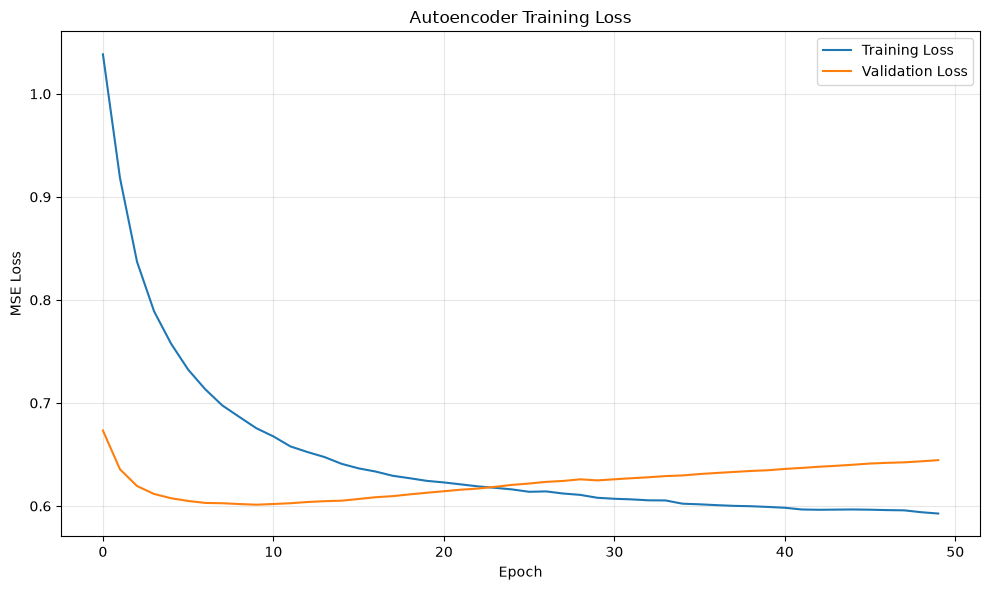

In [23]:
# Autoencoder training loss

plt.figure(figsize=(10, 6))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Autoencoder Training Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Latent Representation

The trained encoder is used to transform the original feature space into a compact 16-dimensional latent representation.

In [58]:
encoder = Model(
    inputs=autoencoder.input,
    outputs=autoencoder.get_layer("latent_space").output
)

X_latent = encoder.predict(X_scaled)

print("Latent shape:", X_latent.shape)

1104/1104 ━━━━━━━━━━━━━━━━━━━━ 1s 734us/step
Latent shape: (35311, 16)


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Evaluate different numbers of clusters
k_values = range(2, 11)
silhouette_scores = []

kmeans_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    kmeans_scores.append(score)

print(f"K={k}, Silhouette Score={score:.4f}")

K=2, Silhouette Score=-0.0340
K=3, Silhouette Score=-0.0323
K=4, Silhouette Score=-0.0933
K=5, Silhouette Score=-0.0785
K=6, Silhouette Score=-0.0514
K=7, Silhouette Score=-0.2104
K=8, Silhouette Score=-0.1852
K=9, Silhouette Score=-0.1974
K=10, Silhouette Score=-0.1788


## 8. K-Means Clustering on Latent Space

In [59]:
# K-Means on Autoencoder latent representation

latent_k_values = range(2, 11)
latent_silhouette_scores = []

for k in latent_k_values:
    kmeans_latent = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    latent_labels = kmeans_latent.fit_predict(X_latent)

    score = silhouette_score(X_latent, latent_labels)
    latent_silhouette_scores.append(score)

    print(f"K={k}: Silhouette Score = {score:.4f}")

best_latent_k = latent_k_values[
    np.argmax(latent_silhouette_scores)
]

best_latent_score = max(latent_silhouette_scores)

print(f"\nBest K: {best_latent_k}")
print(f"Best Silhouette Score: {best_latent_score:.4f}")

K=2: Silhouette Score = 0.7588
K=3: Silhouette Score = 0.6152
K=4: Silhouette Score = 0.5769
K=5: Silhouette Score = 0.6034
K=6: Silhouette Score = 0.5519
K=7: Silhouette Score = 0.5901
K=8: Silhouette Score = 0.5706
K=9: Silhouette Score = 0.5118
K=10: Silhouette Score = 0.5830

Best K: 2
Best Silhouette Score: 0.7588


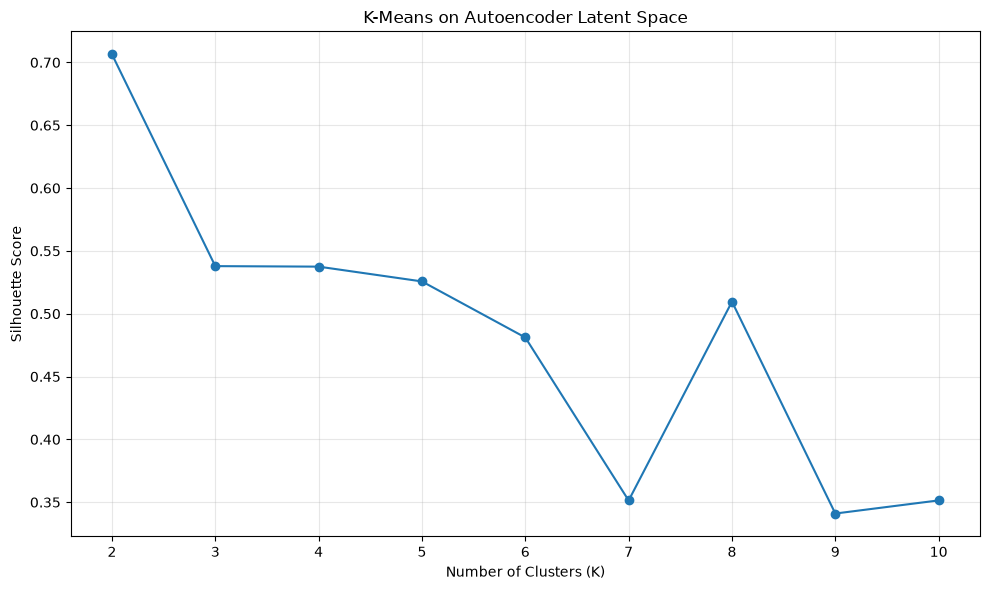

In [27]:
# Compare clustering performance

plt.figure(figsize=(10, 6))

plt.plot(
    list(latent_k_values),
    latent_silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("K-Means on Autoencoder Latent Space")
plt.xticks(list(latent_k_values))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [28]:
# Final K-Means clustering on Autoencoder latent space

final_kmeans = KMeans(
    n_clusters=best_latent_k,
    random_state=42,
    n_init=10
)

final_labels = final_kmeans.fit_predict(X_latent)

print("Final clustering completed.")
print("Number of clusters:", best_latent_k)
print("Silhouette Score:", f"{best_latent_score:.4f}")

print("\nCluster distribution:")
print(pd.Series(final_labels).value_counts().sort_index())

Final clustering completed.
Number of clusters: 2
Silhouette Score: 0.7065

Cluster distribution:
0    33215
1     2096
Name: count, dtype: int64


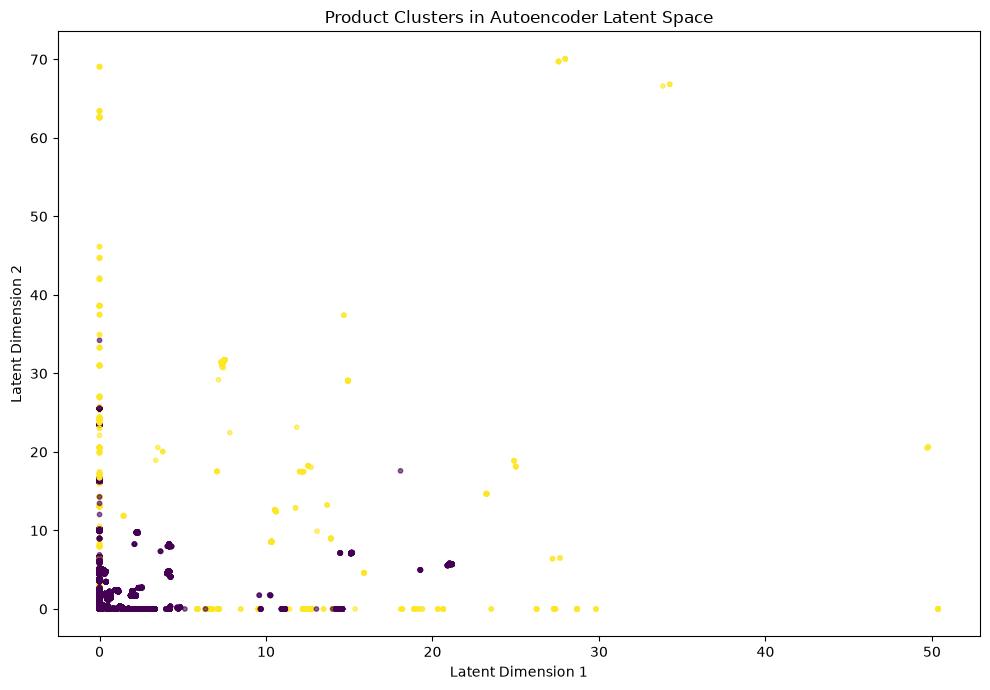

In [29]:
# Visualize clusters using the first two latent dimensions

plt.figure(figsize=(10, 7))

plt.scatter(
    X_latent[:, 0],
    X_latent[:, 1],
    c=final_labels,
    s=10,
    alpha=0.6
)

plt.title("Product Clusters in Autoencoder Latent Space")
plt.xlabel("Latent Dimension 1")
plt.ylabel("Latent Dimension 2")
plt.tight_layout()
plt.show()

## 9. Cluster Analysis & Insights

The final K-Means clusters are analyzed using product categories and merchant information to better understand the characteristics and distribution of each cluster.

In [63]:
# Analyze final clusters

analysis_df = df.copy()
analysis_df["Cluster"] = final_labels

print("=== Cluster Distribution ===")
print(
    analysis_df["Cluster"]
    .value_counts()
    .sort_index()
    .to_frame("Product Count")
)

print("\n=== Cluster Percentage ===")
print(
    (analysis_df["Cluster"].value_counts(normalize=True) * 100)
    .sort_index()
    .round(2)
    .to_frame("Percentage")
)

print("\n=== Top Categories by Cluster ===")
for cluster in sorted(analysis_df["Cluster"].unique()):
    print(f"\nCluster {cluster}:")
    print(
        analysis_df.loc[
            analysis_df["Cluster"] == cluster,
            "Category Label"
        ]
        .value_counts()
        .head(10)
    )
    final_labels = latent_labels

=== Cluster Distribution ===
         Product Count
Cluster               
0                33215
1                 2096

=== Cluster Percentage ===
         Percentage
Cluster            
0             94.06
1              5.94

=== Top Categories by Cluster ===

Cluster 0:
Category Label
Fridge Freezers     5497
Washing Machines    4012
Mobile Phones       3794
Fridges             3581
CPUs                3420
Dishwashers         3413
TVs                 2937
Freezers            2208
Digital Cameras     2207
Microwaves          2146
Name: count, dtype: int64

Cluster 1:
Category Label
TVs                 627
Digital Cameras     490
CPUs                442
Mobile Phones       287
Microwaves          196
Washing Machines     32
Dishwashers          11
Freezers              4
Fridge Freezers       4
Fridges               3
Name: count, dtype: int64


In [64]:
cluster_1_categories = (
    analysis_df.loc[
        analysis_df["Cluster"] == 1,
        "Category Label"
    ]
    .value_counts()
)

print("=== All Categories in Cluster 1 ===")
print(cluster_1_categories.to_string())

=== All Categories in Cluster 1 ===
Category Label
TVs                 627
Digital Cameras     490
CPUs                442
Mobile Phones       287
Microwaves          196
Washing Machines     32
Dishwashers          11
Freezers              4
Fridge Freezers       4
Fridges               3


In [65]:
# Compare category distribution across clusters

category_cluster = pd.crosstab(
    analysis_df["Category Label"],
    analysis_df["Cluster"],
    normalize="columns"
) * 100

print("=== Category Distribution by Cluster (%) ===")
print(category_cluster.round(2).to_string())

=== Category Distribution by Cluster (%) ===
Cluster               0      1
Category Label                
CPUs              10.30  21.09
Digital Cameras    6.64  23.38
Dishwashers       10.28   0.52
Freezers           6.65   0.19
Fridge Freezers   16.55   0.19
Fridges           10.78   0.14
Microwaves         6.46   9.35
Mobile Phones     11.42  13.69
TVs                8.84  29.91
Washing Machines  12.08   1.53


In [66]:
# Top Merchants by Cluster

print("=== Top Merchants by Cluster ===")

for cluster in sorted(analysis_df["Cluster"].unique()):
    print(f"\nCluster {cluster}:")

    print(
        analysis_df.loc[
            analysis_df["Cluster"] == cluster,
            "Merchant ID"
        ]
        .value_counts()
        .head(10)
        .to_string()
    )

=== Top Merchants by Cluster ===

Cluster 0:
Merchant ID
3      2547
6      1591
298    1523
31     1350
119    1239
7      1204
17     1193
293    1177
294    1000
301     901

Cluster 1:
Merchant ID
73     313
26     148
253    126
79      95
126     76
60      74
156     60
19      57
52      55
247     54


In [32]:
# Cluster profile

cluster_profile = (
    analysis_df
    .groupby("Cluster")
    .agg(
        Product_Count=("Product ID", "count"),
        Unique_Categories=("Category ID", "nunique"),
        Unique_Merchants=("Merchant ID", "nunique")
    )
)

cluster_profile["Percentage"] = (
    cluster_profile["Product_Count"]
    / len(analysis_df) * 100
).round(2)

cluster_profile

,Product_Count,Unique_Categories,Unique_Merchants,Percentage
Cluster,,,,
0,33215,10,167,94.06
1,2096,10,140,5.94


In [33]:
# Top 10 categories for each cluster

for cluster in sorted(analysis_df["Cluster"].unique()):
    print(f"\n===== CLUSTER {cluster} =====")
    
    top_categories = (
        analysis_df[analysis_df["Cluster"] == cluster]["Category Label"]
        .value_counts()
        .head(10)
    )
    
    print(top_categories)


===== CLUSTER 0 =====
Category Label
Fridge Freezers     5497
Washing Machines    4012
Mobile Phones       3794
Fridges             3581
CPUs                3420
Dishwashers         3413
TVs                 2937
Freezers            2208
Digital Cameras     2207
Microwaves          2146
Name: count, dtype: int64

===== CLUSTER 1 =====
Category Label
TVs                 627
Digital Cameras     490
CPUs                442
Mobile Phones       287
Microwaves          196
Washing Machines     32
Dishwashers          11
Freezers              4
Fridge Freezers       4
Fridges               3
Name: count, dtype: int64


## 10. DBSCAN Clustering

In [60]:
# DBSCAN clustering on Autoencoder latent space

from sklearn.cluster import DBSCAN

dbscan = DBSCAN(
    eps=0.5,
    min_samples=10
)

dbscan_labels = dbscan.fit_predict(X_latent)

n_clusters_dbscan = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = np.sum(dbscan_labels == -1)

print("DBSCAN Results")
print("Number of clusters:", n_clusters_dbscan)
print("Noise points:", n_noise)

DBSCAN Results
Number of clusters: 212
Noise points: 633


In [61]:
# Calculate Silhouette Score for DBSCAN

mask = dbscan_labels != -1

if n_clusters_dbscan >= 2:
    dbscan_silhouette = silhouette_score(
        X_latent[mask],
        dbscan_labels[mask]
    )

    print("DBSCAN Silhouette Score:", round(dbscan_silhouette, 4))
else:
    dbscan_silhouette = None
    print("Silhouette Score cannot be calculated.")

DBSCAN Silhouette Score: 0.6622


## 11. Model Comparison

In [68]:
# Final model comparison

comparison = pd.DataFrame({
    "Method": [
        "K-Means",
        "K-Means + Autoencoder",
        "DBSCAN + Autoencoder"
    ],
    "Feature Space": [
        "Original (316D)",
        "Latent (16D)",
        "Latent (16D)"
    ],
    "Clusters": [
        best_k,
        best_latent_k,
        n_clusters_dbscan
    ],
    "Noise Points": [
        0,
        0,
        n_noise
    ],
    "Silhouette Score": [
        max(kmeans_scores),
        best_latent_score,
        dbscan_silhouette
    ]
})

comparison

,Method,Feature Space,Clusters,Noise Points,Silhouette Score
0,K-Means,Original (316D),3,0,-0.032252
1,K-Means + Autoencoder,Latent (16D),2,0,0.758847
2,DBSCAN + Autoencoder,Latent (16D),212,633,0.662184


## 12. Conclusion

The clustering experiments show that the original feature space does not provide well-separated product groups using K-Means, achieving a Silhouette Score of -0.0323.

The Autoencoder improved the feature representation by reducing the original 316-dimensional feature space to 16 latent dimensions. K-Means on this latent representation achieved the highest Silhouette Score of 0.7588, identifying 2 clusters.

DBSCAN also identified density-based structures in the latent space, producing 212 clusters and 633 noise points, with a Silhouette Score of 0.6622 calculated on non-noise observations only.

Overall, the results indicate that Autoencoder-based representation learning can improve the clustering structure of the product data. Among the evaluated methods, K-Means on the latent representation provided the strongest Silhouette Score and a more compact clustering solution. However, the resulting clusters were highly imbalanced, and their interpretation was limited by the use of only Merchant ID and Category ID as input features.